## Problem Set 4: Kernel Density Estimation

### Author: Liam Hopkins

#### Generative AI: 

Generative AI (Gemini) was used to assist in completing this assignment.

AI was primarily used for help understanding course concepts and for help with writing code for getting true density of x = 0 using the normal distribution and for plotting the large 3 by 5 grid of density plots in problem 4 part b. I asked the AI tools for possible ways of doing this, read the solutions it gave me, and implemented the ideas into my own code.

In [61]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import norm

In [52]:
# For sketching ecdf
def ecdf_xy(samples):
    x = np.sort(np.asarray(samples))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

# For sketching kde
def kde(X,h_u,K=30):
    n = len(X)
    X = np.array(X)
    x_grid = np.linspace( X.min()-2*h_u, X.max()+2*h_u, K) # Create a grid to plot
    I = np.abs( x_grid[:,None] - X[None,:]) < h_u # Broadcast the indicator comparison
    f_hat = np.sum(I,axis=1)/(2 * n * h_u) # Compute kde
    plt.step(x_grid,f_hat,where='mid')
    plt.fill_between(x_grid,f_hat,step='mid')
    plt.title('Uniform Kernel Density Estimator (Blocky)')
    plt.show()
    return x_grid, f_hat

# Used for calculating f_hat with uniform kernel
def uniform_kde(X, x, h):
    X = np.asarray(X)
    n = len(X)
    sum = 0

    for i in range(n):
        if np.abs(X[i] - x) < h:
            sum += 1

    return sum / (2 * n * h)

# Used for calculating f_hat with a gaussian kernel
def gaussian_kde(X, x, h):
    """f_hat_h(x) on `grid`, Gaussian kernel."""
    X = np.asarray(X)
    n = len(X)
    Z = (X - x) / h
    phi = np.exp(-Z**2 / 2) / np.sqrt(2 * np.pi)
    return sum(phi) / (n * h)

# Used for calculating the expected value
def expected_f_hat(X, x, h):
    n = len(X)
    x_plus_h = sum([obs <= (x+h) for obs in X]) / n
    x_minus_h = sum([obs <= (x-h) for obs in X]) / n

    return (x_plus_h - x_minus_h) / (2 * h)

#### Problem 1

Suppose the data are `[1, 1.75, 2, 3, 3.25, 4]`.

**Part A**

Sketch the empirical cumulative distribution function.

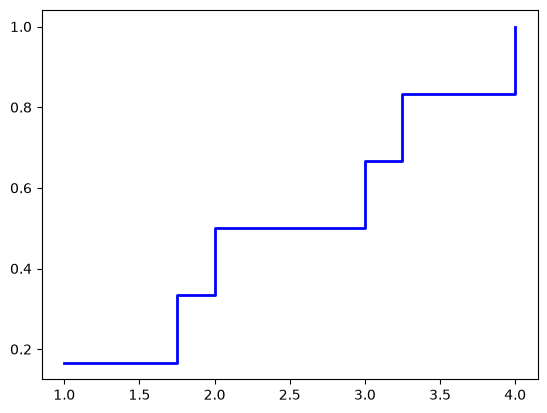

In [6]:
data = [1, 1.75, 2, 3, 3.25, 4]

x, y = ecdf_xy(data)
plt.step(x, y, where='post', color='blue', lw=2)

**Part B**

Sketch the uniform kernel density estimator for a bandwidth of `h = 0.2`.

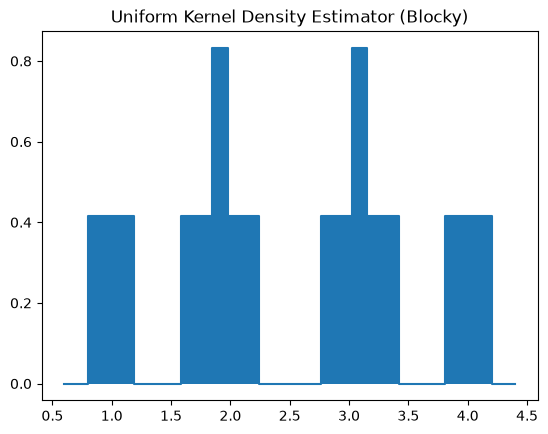

(array([0.6       , 0.73103448, 0.86206897, 0.99310345, 1.12413793,
        1.25517241, 1.3862069 , 1.51724138, 1.64827586, 1.77931034,
        1.91034483, 2.04137931, 2.17241379, 2.30344828, 2.43448276,
        2.56551724, 2.69655172, 2.82758621, 2.95862069, 3.08965517,
        3.22068966, 3.35172414, 3.48275862, 3.6137931 , 3.74482759,
        3.87586207, 4.00689655, 4.13793103, 4.26896552, 4.4       ]),
 array([0.        , 0.        , 0.41666667, 0.41666667, 0.41666667,
        0.        , 0.        , 0.        , 0.41666667, 0.41666667,
        0.83333333, 0.41666667, 0.41666667, 0.        , 0.        ,
        0.        , 0.        , 0.41666667, 0.41666667, 0.83333333,
        0.41666667, 0.41666667, 0.        , 0.        , 0.        ,
        0.41666667, 0.41666667, 0.41666667, 0.        , 0.        ]))

In [ ]:
# KDE with h = 0.2
kde(data, 0.2)

**Part C**

Compute the Silverman bandwidth for the uniform kernel using `h = 1.84 * sd(X) * n**{-0.2}`.

In [10]:
sd = np.std(data)
n = len(data)

h = 1.84 * sd * n**(-0.2)
print(f'Silverman bandwidth = {h:.3f}')

Silverman bandwidth = 1.299


**Part d**

Sketch the uniform kernel density estimator for the Silverman bandwidth.

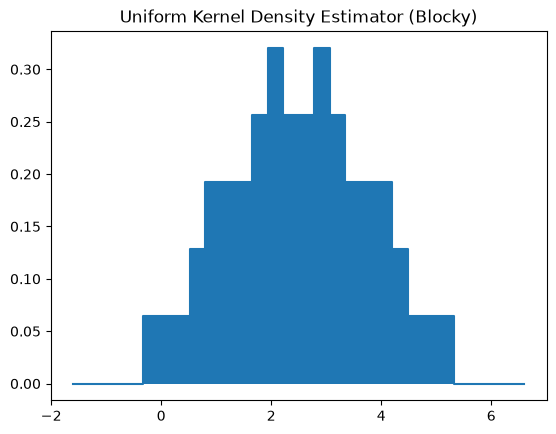

(array([-1.59833408, -1.31569035, -1.03304662, -0.75040289, -0.46775916,
        -0.18511543,  0.0975283 ,  0.38017203,  0.66281576,  0.94545949,
         1.22810322,  1.51074695,  1.79339068,  2.07603441,  2.35867814,
         2.64132186,  2.92396559,  3.20660932,  3.48925305,  3.77189678,
         4.05454051,  4.33718424,  4.61982797,  4.9024717 ,  5.18511543,
         5.46775916,  5.75040289,  6.03304662,  6.31569035,  6.59833408]),
 array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.06414366, 0.06414366, 0.06414366, 0.12828733, 0.19243099,
        0.19243099, 0.19243099, 0.25657465, 0.32071832, 0.25657465,
        0.25657465, 0.32071832, 0.25657465, 0.19243099, 0.19243099,
        0.19243099, 0.12828733, 0.06414366, 0.06414366, 0.06414366,
        0.        , 0.        , 0.        , 0.        , 0.        ]))

In [11]:
# KDE with h = 0.2
kde(data, h)

**Part e**

How are b and d similar or different?


**Answer:** The KDE sketched in d looks a lot more like a normal distribution than the one sketched in c. c's KDE makes it hard to tell any kind of distribution, as it just looks like vertical bars where our observations are. This makes sense, as a lower $h$ produces a KDE closer to the real $f(x)$. In this case, our data set is so small, there is no real distribution to see.

#### Problem 2

Suppose the data `X = [-1, -0.5, 0, 0.5, 1]` were drawn from a standard Normal distribution.

**Part a**

Using the uniform kernel with `h = 0.6`, compute the realized KDE at `x = 0`, `f_hat_h(0)`, directly from these five numbers.

In [58]:
X = [-1, -0.5, 0, 0.5, 1]

f_hat_h = uniform_kde(X, 0, 0.6)
print(f'f_hat_h(0) = {f_hat_h}')

f_hat_h(0) = 0.5


**Part b**

Now compute `E[f_hat_h(0)]` at the same `h = 0.6`.

In [59]:
expected = expected_f_hat(X, 0, 0.6)
print(f'E[f_hat_h(0)] = {expected}')

E[f_hat_h(0)] = 0.5000000000000001


**Part c**

Calculate the true density at `x=0`, using the Normal distribution.

In [65]:
density = norm.pdf(0, loc=0, scale=1)
print(density)

0.3989422804014327


**Part d**

Are b and c equal? What does this mean about bias? (Keep in mind, truly proving anything about bias would require us to compare `E[f_hat_h]` to the Normal distribution for all x; calculating this at one point is only an indication of what is going on that you can extrapolate from.)

**Answer:** No, b and c are not equal. This means we can guess that there is some bias in the estimate `E[f_hat_h]`, as if it were an unbiased estimator b and c would be equal.

**Part e**

Recompute `E[f_hat_h(0)]` from (b) at a much smaller bandwidth, `h = 0.1`. What happens to the gap between `E[f_hat_h(0)]` and `f(0)` as `h` shrinks?

In [60]:
expected = expected_f_hat(X, 0, 0.1)
print(f'E[f_hat_h(0)] = {expected}')

E[f_hat_h(0)] = 0.9999999999999998


As `h` shrinks, we see the gap between `E[f_hat_h(0)]` and `f(0)` increase.

**Part f**

Is `f_hat_h` a consistent estimator? Explain your reasoning.

**Answer:** Yes, `f_hat_h` is a consistent estimator. This is because as n increases, the bias continues to shrink. Of course it will never quite hit the real value, but it will continue to get closer and closer consistently. 

**Part g**

What are the main considerations in choosing a bandwidth value `h`?

**Answer:** The first main considerations in choosing `h` is your sample size. As we saw in the example above, the larger your sample size, the smaller `h` you should use. With smaller sample sizes, a very small `h` may not be optimal. The second one is the standard deviation. You want to pick and `h` that will lead to other data points falling in the x+h x-h bounds, so its important to consider the standard deviation to determine how large `h` needs to be to. If points are very spread out, `h` may need to be greater.

#### Problem 3

Suppose the data are `X = [5, 7, 7, 8, 10]`, and fix the bandwidth at `h = 1.5` for both kernels below.

**Part a**

Compute the uniform-kernel KDE, `f_hat_h(x)`, at `x = 6.0`, `x = 6.5`, `x = 7.0`, `x = 8.0`, and `x = 8.5`.

In [19]:
X = [5, 7, 7, 8, 10]
h = 1.5
x_values = [6, 6.5, 7, 8, 8.5]
uniform = []

for x in x_values:
    uniform.append(uniform_kde(X, x, h))

uniform

[0.2, 0.13333333333333333, 0.2, 0.2, 0.06666666666666667]

**Part b**

Compute the Gaussian-kernel KDE at the same five values of `x`, using the same `h = 1.5`.

In [26]:
gauss = []

for x in x_values:
    gauss.append(gaussian_kde(X, x, h))

gauss

[np.float64(0.15116667696891303),
 np.float64(0.16865730580239766),
 np.float64(0.17804448100191994),
 np.float64(0.16744524435137584),
 np.float64(0.1506023053792177)]

**Part c**

Your part (a) values should jump abruptly between some of these five points, while your part (b) values should change smoothly. Identify where the biggest jump in (a) happens, and explain in terms of the two kernel shapes -- not just "one is smoother" -- why that jump exists in the uniform case but not the Gaussian case.

**Answer:** The biggest jump in (a) happens when going from `x = 8.0` to `x = 8.5`. The reason this jump occurs is because of the extra noise in the uniform density curve. The uniform KDE is a bunch of individual uniform density curves for each observation, which adds measurement error. The Gaussian KDE does not have as much error, so it is able to avoid having the abrupt jumps seen in the uniform curve.

**Part d**

Why might you prefer one kernel over the other in practice?

**Answer:** The abrupt jumps in the uniform curve are not very realistic, so if you are trying to model something in the real world the Gaussian version makes more sense.

#### Problem 4

Load `./data/heart_failure_clinical_records_dataset.csv`.

In [29]:
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


**Part a**

Plot a kernel density estimate of `ejection_fraction`.

[Text(0.5, 1.0, 'Gaussian KDE (Smooth)')]

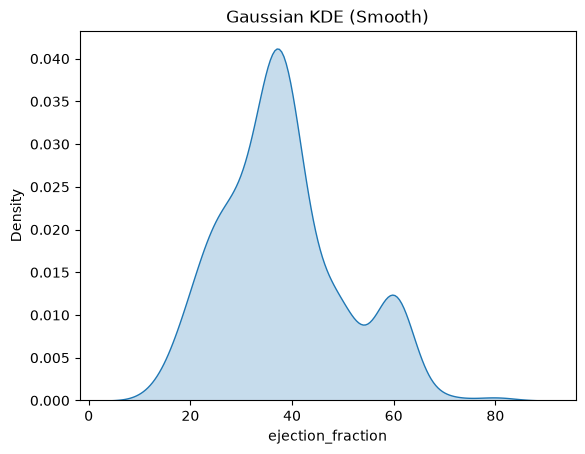

In [32]:
# We will use the Gaussian-kernel KDE
sns.kdeplot( data = df, x = 'ejection_fraction', fill = True).set(title='Gaussian KDE (Smooth)')

**Part b**

Use Pandas' `df.sample(frac=1.0, replace=True)` to resample the data 15 times with replacement, plotting the kernel density estimtes for each sample.

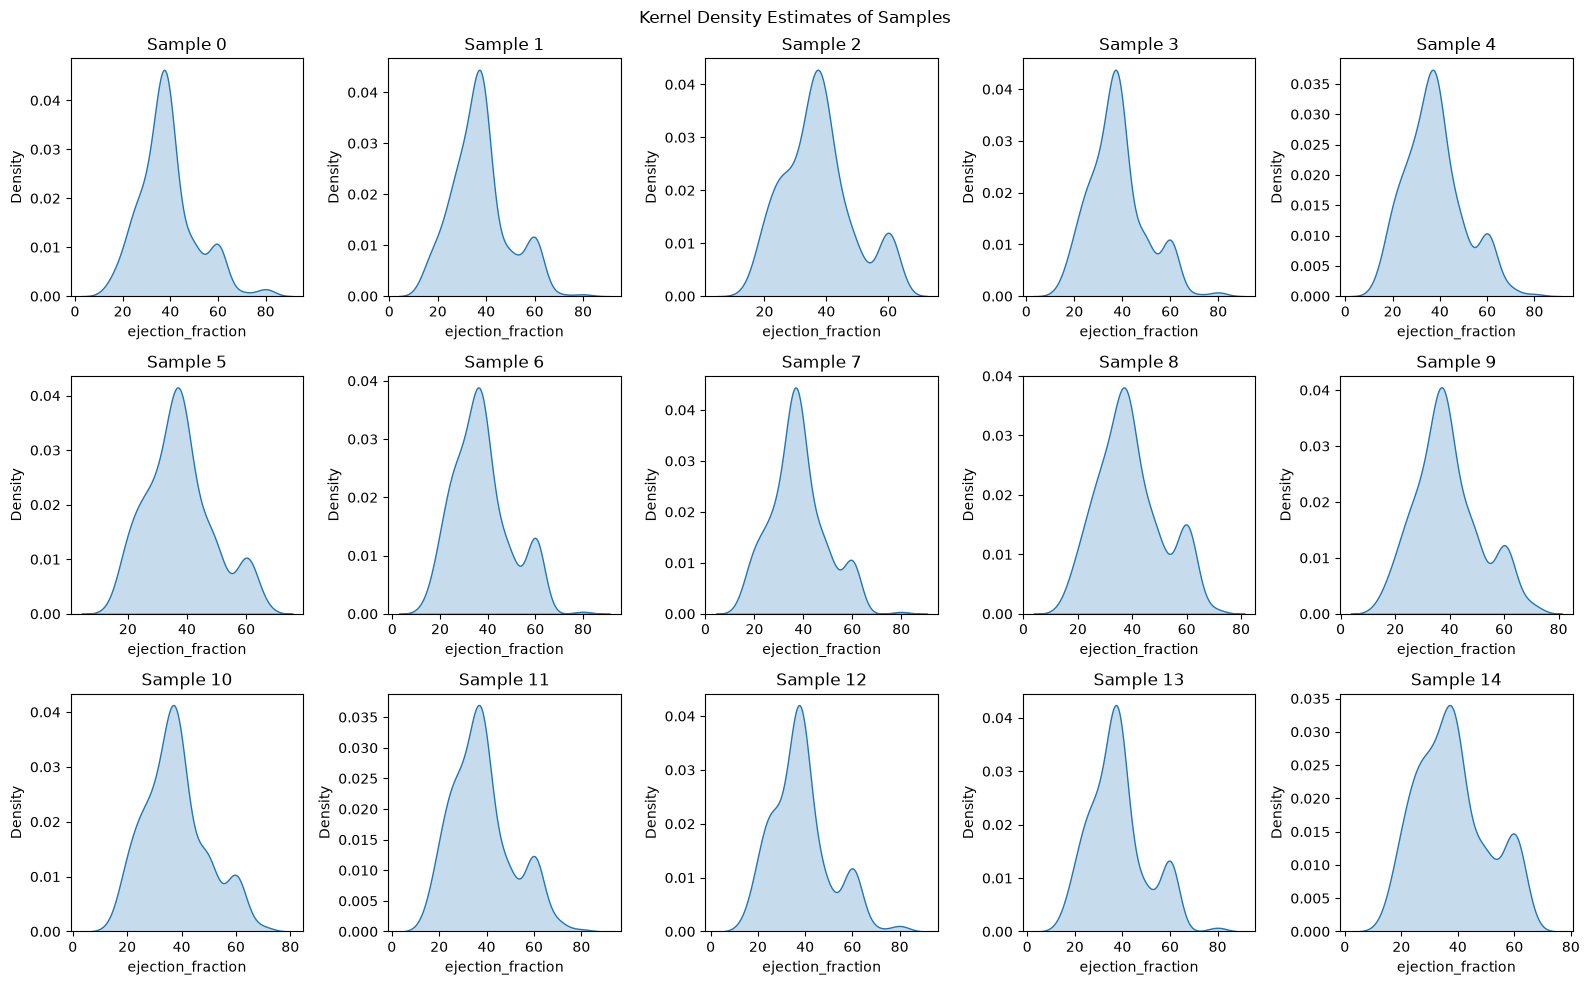

In [45]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
axes = axes.flatten()
for i in range(len(axes)):
    sample = df.sample(frac=1.0, replace=True)
    sns.kdeplot(data=sample, x='ejection_fraction',
                fill = True, ax=axes[i])
    axes[i].set_title(f'Sample {i}')
fig.suptitle('Kernel Density Estimates of Samples')
plt.tight_layout(); plt.show()

**Part c**

For what values of `ejection_fraction` is the original plot reliable? For which values is there noticeable variation in your plots of the resampled data?

**Answer:** The original plot is reliable for `ejection_fraction` values from 0 to around 50. There is lots of data for these values to work with, so the plot is able to represent them well. For values above 50, this is not the case, and we see this in the resampled data. The peaks of these values show lots of variation in the resampled plots. Another example of noticeable variation is some samples contain large values like 80 and above, while some do not.